In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az
import ICIW_Plots
from scipy.integrate import odeint
import pytensor as pt
from HSA_Cam_A_006_jaxOp import (
    bmodel,
    bmodel_batch,
    plot_true_data,
    plot_observed_data,
    plot_inference,
    model_inference,
    theta_true,
    y0_true,
    sigma,
)
from HSA_Cam_A_006_lib_jaxOP import _forward_solve, _forward_solve_batch
import xarray

pt.config.mode = "JAX"

In [2]:
plt.style.use("ICIWstyle")

## The base model

In [3]:
# Times for observation
times = np.linspace(0, 1 * 60 * 60, 100, dtype=np.float64)
times_batch = np.tile(times, (6, 1))
T_vals = np.array([280.0, 300.0, 320.0, 350.0, 380.0, 400.0], dtype=np.float64)
theta = theta_true.copy()
theta_batch = np.tile(theta, (6, 1))
theta_batch[:, 1] = T_vals  # varying temperature
y0_true_batch = np.tile(y0_true, (6, 1))

y_true = xarray.DataArray(
    np.zeros((len(T_vals), len(times), 5)),
    dims=["temperature", "time", "state"],
    coords={
        "temperature": T_vals.tolist(),
        "time": times,
        "state": ["n_g_con", "c_Al", "c_Bl", "c_Cl", "c_Dl"],
    },
)
y_true[:, :, :] = _forward_solve_batch(y0_true_batch, times_batch, theta_batch)
y_true[:, :, 0] *= 1000  # convert m3 to L H2 used (up to a constant atleast)

# Add noise
t_obs = times_batch[:, ::10]
y_obs = np.random.normal(y_true, sigma)[:, ::10, :]  # downsample and add noise
y_obs = xarray.DataArray(
    y_obs,
    dims=["temperature", "time", "state"],
    coords={
        "temperature": T_vals.tolist(),
        "time": t_obs[0, :],
        "state": ["n_g_con", "c_Al", "c_Bl", "c_Cl", "c_Dl"],
    },
)

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


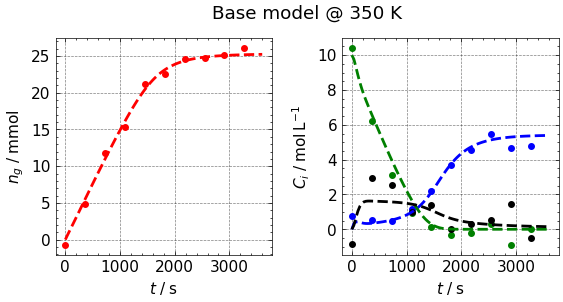

In [4]:
## Plotting the base model
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$t\;/\;\mathrm{s}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)
plot_true_data(axs, times_batch[4, :], y_true[4, :, :])
plot_observed_data(axs, t_obs[4, :], y_obs[4, :, :])
plt.suptitle("Base model @ 350 K")
plt.show()

## Sample the prior distribution

In [5]:
model_batch = bmodel_batch(t_obs, T_vals, y_obs.values)
with model_batch:
    prior_idata = pm.sample_prior_predictive(samples=1000, random_seed=23489)

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pytensor\link\jax\linker.py:32: UserWarning: The RandomType SharedVariables [RNG(<Generator(PCG64) at 0x1C84037B840>), RNG(<Generator(PCG64) at 0x1C8405C42E0>), RNG(<Generator(PCG64) at 0x1C8405C4120>), RNG(<Generator(PCG64) at 0x1C8405C43C0>), RNG(<Generator(PCG64) at 0x1C840379A80>), RNG(<Generator(PCG64) at 0x1C8405C7A00>), RNG(<Generator(PCG64) at 0x1C840379B60>)] will not be used in the compiled JAX graph. Instead a copy will be used.
  warnings.warn(
Sampling: [A01, A02, EA1, EA2, LH2, kla, sigma]


c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


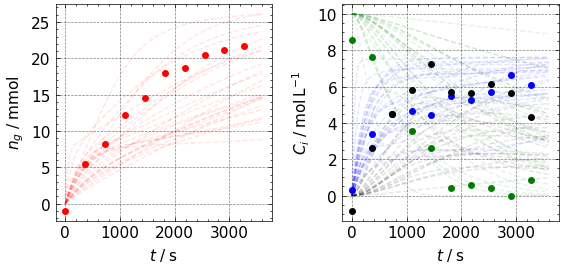

In [6]:
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$t\;/\;\mathrm{s}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)
plot_observed_data(axs, t_obs[2, :], y_obs[2, :, :])
plot_inference(
    axs,
    prior_idata,
    times=times,
    num_samples=25,
    lw=1,
    alpha=0.1,
)

## Sample the posterior given the six profiles at the given temperatures

In [7]:
vars_list = list(model_batch.values_to_rvs.keys())[:-1]
with model_batch:
    posterior_idata = pm.sample(
        # step=[pm.DEMetropolisZ(vars_list)],
        draws=20,
        tune=5,
        # target_accept=0.9,
        random_seed=23489,
        return_inferencedata=True,
        # nuts_sampler="numpyro",
        cores=4,
    )

Only 20 samples per chain. Reliable r-hat and ESS diagnostics require longer chains for accurate estimate.
Initializing NUTS using jitter+adapt_diag...


RuntimeError: Unexpected tangent. `*args` and `**kwargs` to `filter_custom_vjp` cannot be autodifferentiated.
Apply node that caused the error: Add(-18.872262747561688, Switch.0, Subtensor{i}.0, Switch.0, Subtensor{i}.0, Mul.0, Switch.0, Subtensor{i}.0, Mul.0, Switch.0, Subtensor{i}.0, Sum{axes=None}.0)
Toposort index: 63
Inputs types: [TensorType(float64, shape=()), TensorType(float64, shape=()), TensorType(float64, shape=()), TensorType(float64, shape=()), TensorType(float64, shape=()), TensorType(float64, shape=()), TensorType(float64, shape=()), TensorType(float64, shape=()), TensorType(float64, shape=()), TensorType(float64, shape=()), TensorType(float64, shape=()), TensorType(float64, shape=())]
Inputs shapes: [(6,)]
Inputs strides: [(8,)]
Inputs values: ['not shown']
Outputs clients: [[output[0](Add.0)]]

Backtrace when the node is created (use PyTensor flag traceback__limit=N to make it longer):
  File "c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\inter

In [ ]:
az.ess(posterior_idata, method="bulk", relative=False)["EA1"]

<xarray.DataArray 'EA1' ()> Size: 8B
array(7.24385736)

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


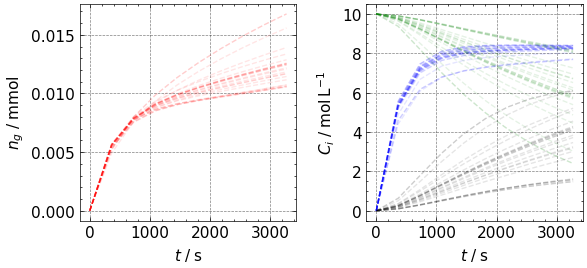

In [ ]:
post_data = az.extract(
    posterior_idata,
    group="posterior",
    num_samples=25,
    var_names=["y_hat"],
)

fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$t\;/\;\mathrm{s}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)

for i in range(25):
    # print(f"Plotting sample {i+1}/25")
    plot_true_data(
        axs,
        t_obs[2, :],
        post_data.values[0, :, :, i],
        lw=1,
        alpha=0.1,
    )
plt.show()

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


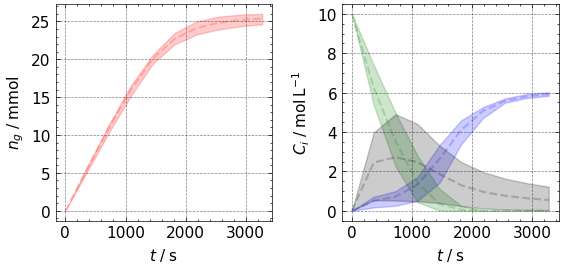

In [ ]:
post_data = az.extract(
    posterior_idata,
    group="posterior",
    var_names=["y_hat"],
).copy()
# display(post_data)

post_data[:, :, 0, :] *= 1000

fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$t\;/\;\mathrm{s}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)

# plot_true_data(axs, times, y_true, lw=2)
i = 3

plot_true_data(
    axs,
    t_obs[2, :],
    post_data.values.mean(axis=3)[i, :, :],
    lw=1.5,
    alpha=0.2,
)

axs[0, 0].fill_between(
    t_obs[2, :],
    np.percentile(post_data.values, 5, axis=3)[i, :, 0],
    np.percentile(post_data.values, 95, axis=3)[i, :, 0],
    color="red",
    alpha=0.2,
    zorder=0,
)

axs[0, 1].fill_between(
    t_obs[2, :],
    np.percentile(post_data.values, 5, axis=3)[i, :, 1],
    np.percentile(post_data.values, 95, axis=3)[i, :, 1],
    color=["blue"],
    alpha=0.2,
    zorder=0,
)
axs[0, 1].fill_between(
    t_obs[2, :],
    np.percentile(post_data.values, 5, axis=3)[i, :, 2],
    np.percentile(post_data.values, 95, axis=3)[i, :, 2],
    color=["green"],
    alpha=0.2,
    zorder=0,
)
axs[0, 1].fill_between(
    t_obs[2, :],
    np.percentile(post_data.values, 5, axis=3)[i, :, 3],
    np.percentile(post_data.values, 95, axis=3)[i, :, 3],
    color=["black"],
    alpha=0.2,
    zorder=0,
)


plt.show()

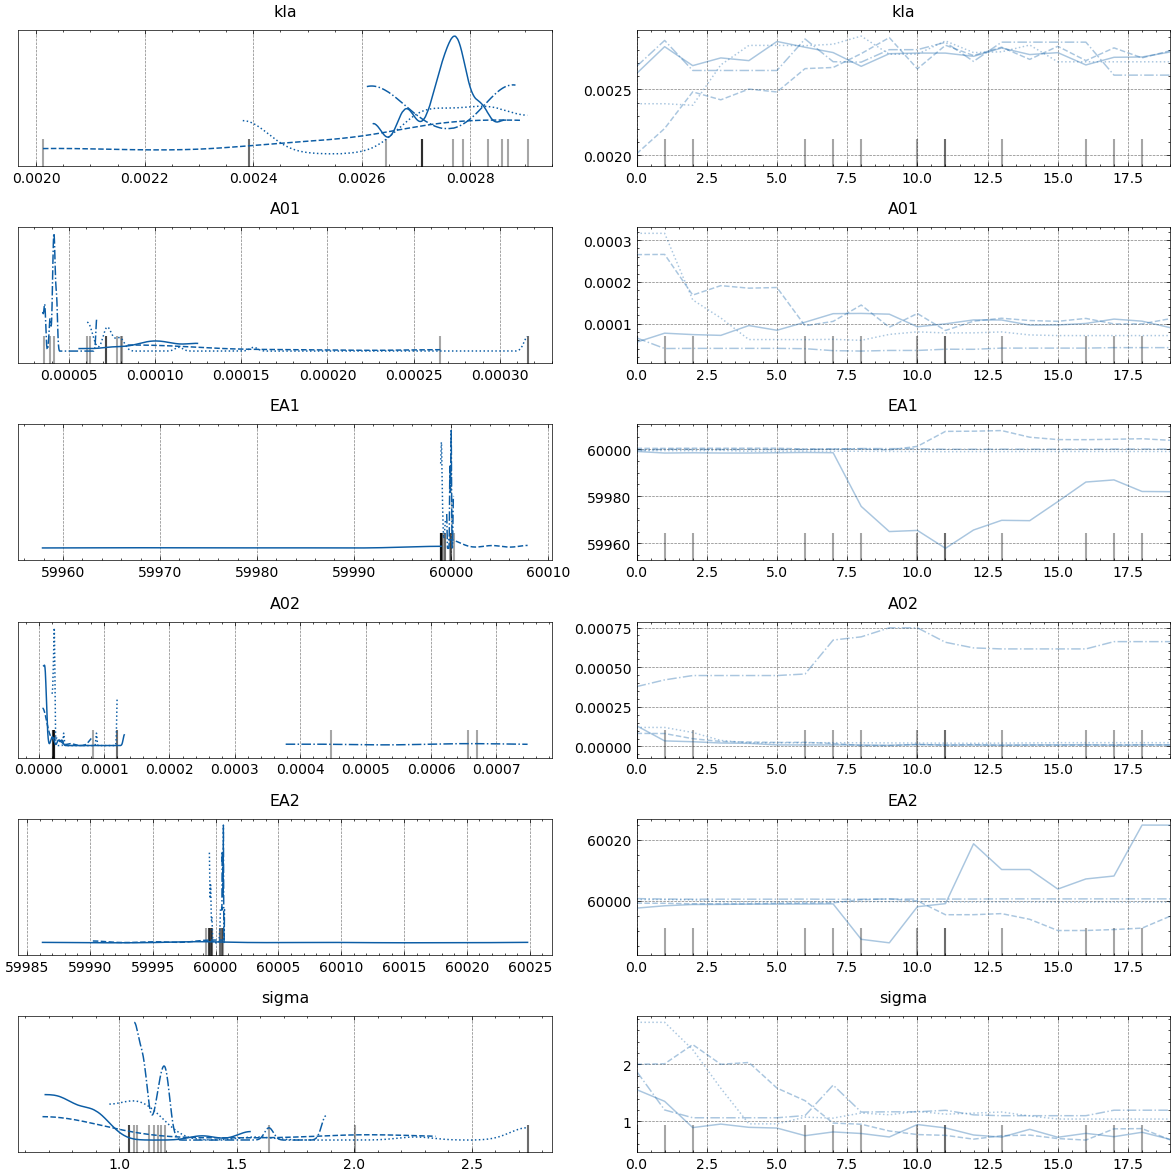

In [ ]:
az.plot_trace(
    posterior_idata,
    var_names=[
        "kla",
        "A01",
        "EA1",
        "A02",
        "EA2",
        "sigma",
    ],
)
plt.show()

Text(0.5, 0.98, 'Posterior model @ 350 K')

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


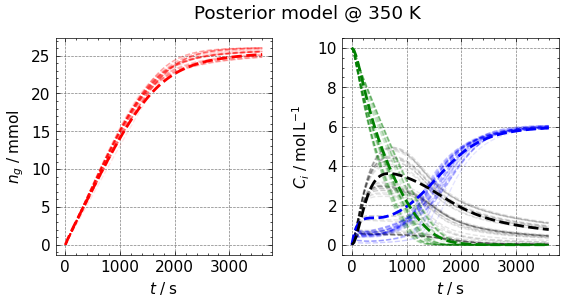

In [ ]:
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$t\;/\;\mathrm{s}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)

plot_inference(
    axs,
    posterior_idata,
    times=times,
    group="posterior",
    num_samples=50,
    theta_indep=(10e5, 350),
    lw=1,
    alpha=0.1,
)
# index xarray where T=350

plot_true_data(axs, times, y_true.sel(temperature=350))
plt.suptitle("Posterior model @ 350 K")

Text(0.5, 0.98, 'Posterior model @ 300 K')

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


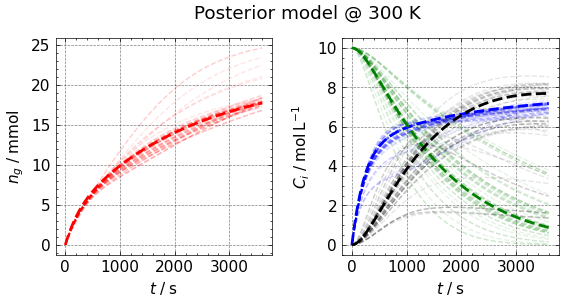

In [ ]:
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$t\;/\;\mathrm{s}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)

plot_inference(
    axs,
    posterior_idata,
    times=times,
    group="posterior",
    num_samples=50,
    theta_indep=(10e5, 300),
    lw=1,
    alpha=0.1,
)
plot_true_data(axs, times, y_true.sel(temperature=300))
plt.suptitle("Posterior model @ 300 K")

### How does the posterior behave given extrapolation?

In [ ]:
Ts = np.linspace(280, 400, 50)
y_hatses = []
y_trues = []
for T in Ts:
    y_hats = model_inference(
        posterior_idata,
        y0_true,
        times,
        theta_indep=(10e5, T),
        n_samples=99,
    )
    # print(y_hats.shape)
    y_hatses.append(y_hats)
    y_trues.append(
        _forward_solve(
            t=times,
            y0=y0_true,
            theta=np.array((theta_true[0], T, *theta_true[2:])),
        )
    )
y_hatses = np.array(y_hatses)
y_trues = np.array(y_trues)

ValueError: could not broadcast input array from shape (80,5) into shape (99,5)

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


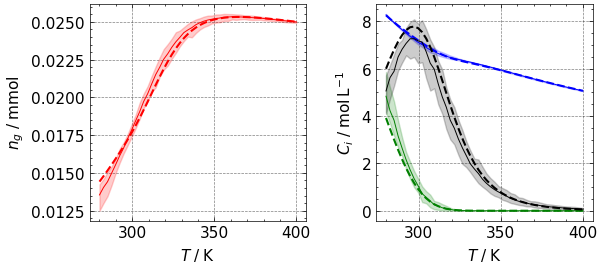

In [ ]:
mean_y_hat = y_hatses.mean(axis=1)
CI5 = np.percentile(y_hatses, 5, axis=1)
CI95 = np.percentile(y_hatses, 95, axis=1)

fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$T\;/\;\mathrm{K}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)
axs[0, 0].plot(Ts, mean_y_hat[:, -1, 0], color="red", lw=0.7)
axs[0, 0].plot(Ts, y_trues[:, -1, 0], "--", color="red")
axs[0, 0].fill_between(Ts, CI5[:, -1, 0], CI95[:, -1, 0], color="red", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -1, 1], color="blue", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -1, 1], "--", color="blue")
axs[0, 1].fill_between(Ts, CI5[:, -1, 1], CI95[:, -1, 1], color="blue", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -1, 2], color="green", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -1, 2], "--", color="green")
axs[0, 1].fill_between(Ts, CI5[:, -1, 2], CI95[:, -1, 2], color="green", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -1, 3], color="black", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -1, 3], "--", color="black")
axs[0, 1].fill_between(Ts, CI5[:, -1, 3], CI95[:, -1, 3], color="black", alpha=0.2)